In [1]:
import torch
import kagglehub
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder

from model.VAE import VAE
import matplotlib.pyplot as plt

/home/vansh/.venvs/core/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DEVICE = "cpu"

vae = VAE(latent_dim=512, device=DEVICE, dtype=torch.float32)

checkpoint = torch.load("checkpoints/vae_epoch_250.pt", map_location=DEVICE)
vae.load_state_dict(checkpoint["model_state_dict"])


<All keys matched successfully>

### Generated Images

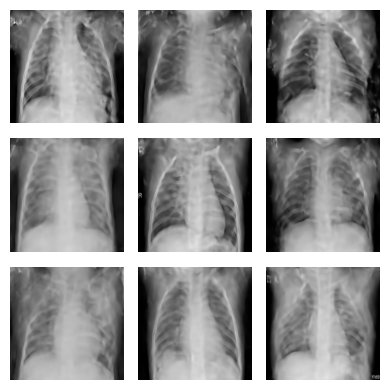

In [3]:
rows, cols = 3, 3

generated_images = vae.sample(num_samples=rows * cols)

fig, axes = plt.subplots(rows, cols, figsize=(4, 4))
for i, image in enumerate(generated_images):
    image = image.detach().cpu().numpy().transpose(1, 2, 0)
    axes[i//cols, i%cols].imshow(image)
    axes[i//cols, i%cols].axis("off")


plt.tight_layout()

### Real Images

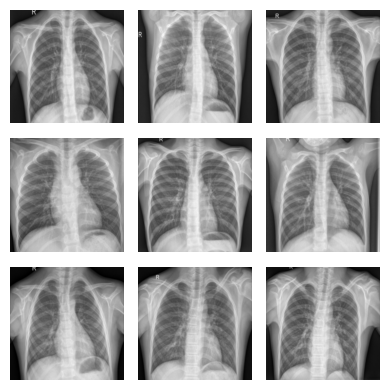

In [4]:
dataset_path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
transform = transforms.Compose([
    transforms.Resize((224, 224)),       # Resize images to a standard size
    transforms.ToTensor(),                # Convert images to PyTorch Tensors
])

dataset = ImageFolder(root=dataset_path, transform=transform)
fig, axes = plt.subplots(rows, cols, figsize=(4, 4))
for i in range(rows * cols):
    image, _ = dataset[i]
    image = image.detach().cpu().numpy().transpose(1, 2, 0)
    axes[i//cols, i%cols].imshow(image)
    axes[i//cols, i%cols].axis("off")

plt.tight_layout()
